<a href="https://colab.research.google.com/github/Sukruth99/Agent-app-Flutter/blob/main/sensor_sleuth_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sensor Sleuth: The Smart Campus Mystery
### A type-along Python game for big data analytics in IoT

Welcome, new hire! You've just joined the Smart Campus Data Team.

The campus has 40 IoT sensors spread across 5 buildings. Every sensor reports
temperature, humidity, CO₂ and battery level once a minute, all day, every day.
That's over 400,000 readings in a single week!

Something strange happened last week. Your boss needs answers, and the only way to get them is to analyze the data with Python. Solve 7 cases to earn a detective rank, then crack the extra credit case if you dare.

---

### How to play

| You see | What you do |
|---|---|
| ⌨️ **Type this** | Run the cell below it to get a typing box. Type the code shown into the box yourself (pasting is blocked, typing is how it sticks!), then press **Shift + Enter** in the box to run it. |
| ▶️ **Run this** | The cell is already filled in. Just run it. |
| ✍️ **Your turn** | Write your **own** code in the cell to answer the question, or replace the `___` blanks to finish the code. There's usually more than one right answer. Stuck? Click **💡 Hint**. |
| 🎯 **Case** | Replace `None` with your answer and run the cell to submit it. |
| 🐞 **Bug check** | Log every error you hit and how you fixed it in your **Bug Journal**. |

**Scoring:** each case is worth **10 points** (the boss case is worth **20**). The 🌟 **Extra credit** round near the end adds up to **10 bonus points**.
A wrong answer costs **2 points**. A hint costs **3 points**: type `hint(1)` for a hint on case 1.
Check your score any time with `scoreboard()`.

If you see an error, read the last line of the message first. It usually tells you exactly what went wrong (often a typo!).

### 🐞 Your Bug Journal

Errors are not failures, they're *clues*. Professional programmers hit errors all day; what makes them fast is that they recognize the error types and remember what fixed them last time. You can only learn this skill by practice.

Every time you hit an error, record it with `log_error(level, error, fix)`:
* **error**: the last line of the error message, e.g. "NameError: name 'sns' is not defined"
* **fix**: what you did to solve it, e.g. "I hadn't run the import cell, so I ran it"

There's a 🐞 **Bug check** cell at the end of every level to remind you. At the end you'll save your journal and hand it in. Log 3 or more bugs to earn the Bug Hunter badge!

**Error decoder** (the most common ones you'll meet today)

| Error | What it usually means |
|---|---|
| `NameError` | You used a name Python doesn't know yet: a typo, or a cell above wasn't run. |
| `KeyError` | You asked for a column (or label) that doesn't exist. Check the spelling with `df.columns`. |
| `SyntaxError` | Python can't read the line: a missing bracket, quote, comma or colon. |
| `IndentationError` | The spaces at the start of a line are wrong (common in `for` loops). |
| `TypeError` | You gave a function the wrong kind of thing, or the wrong number of things. |
| `AttributeError` | You used a `.something` that doesn't exist, often a typo like `df.heda()`. |

## *Run the below cell every session to set up the game!*

In [ ]:
# @title
# ▶️ RUN THIS CELL. It sets up the typing boxes used in every ⌨️ cell (pasting is blocked).
import ast, uuid
import IPython
import matplotlib.pyplot as _plt
from matplotlib import pyplot as plt
from IPython.display import display, HTML
import numpy as np
import pandas as pd
import seaborn as sns
import time
import base64, json


try:
    from google.colab import output as _colab_output
except ImportError:
    _colab_output = None

_BOX_HTML = r"""
<textarea id="BOX_ID" rows="4" spellcheck="false" autocomplete="off" autocapitalize="off"
  placeholder="Type the code here, then press Shift + Enter to run it."
  style="width:95%; font-family:monospace; font-size:14px; tab-size:4; overflow:hidden"></textarea><br>
<button id="BOX_ID_run">▶ Run (Shift + Enter)</button>
<span id="BOX_ID_msg" style="color:#c0392b; margin-left:8px; font-family:sans-serif"></span>
<div id="BOX_ID_out"></div>
<script>
(function () {
  const box = document.getElementById("BOX_ID");
  const msg = document.getElementById("BOX_ID_msg");
  const out = document.getElementById("BOX_ID_out");

  // Block every way of pasting or dropping text into the box
  function blocked(e) {
    e.preventDefault();
    msg.textContent = "No pasting! Type it yourself, that's how it sticks.";
    setTimeout(() => { msg.textContent = ""; }, 3000);
  }
  box.addEventListener("paste", blocked);
  box.addEventListener("drop", blocked);
  box.addEventListener("beforeinput", e => {
    if (e.inputType.startsWith("insertFromPaste") || e.inputType === "insertFromDrop") blocked(e);
  });

  function run() {
    out.innerHTML = "";
    google.colab.kernel.invokeFunction("sensor_sleuth.run_typed_code", [box.value, "BOX_ID_out"], {});
  }

  box.addEventListener("keydown", e => {
    if (e.key === "Enter" && e.shiftKey) {
      e.preventDefault();
      run();
    } else if (e.key === "Enter") {
      // Keep the current line's indent, and add 4 spaces after a line ending in ":"
      e.preventDefault();
      const line = box.value.slice(0, box.selectionStart).split("\n").pop();
      let indent = line.match(/^ */)[0];
      if (line.trimEnd().endsWith(":")) indent += "    ";
      box.setRangeText("\n" + indent, box.selectionStart, box.selectionEnd, "end");
      box.dispatchEvent(new Event("input"));
    } else if (e.key === "Tab") {
      e.preventDefault();
      box.setRangeText("    ", box.selectionStart, box.selectionEnd, "end");
    }
  });
  box.addEventListener("input", () => {
    box.style.height = "auto";
    box.style.height = box.scrollHeight + "px";
  });
  document.getElementById("BOX_ID_run").addEventListener("click", run);
})();
</script>
"""


def _run_typed_code(code, result_id):
    """Run code typed into a box like a normal cell: show the last line's value, charts and errors."""
    ip = IPython.get_ipython()
    with _colab_output.redirect_to_element("#" + result_id):
        try:
            tree = ast.parse(code)
        except SyntaxError:
            ip.showsyntaxerror()
            return
        last = None
        if tree.body and isinstance(tree.body[-1], ast.Expr):
            last = ast.Expression(tree.body.pop().value)
        try:
            exec(compile(tree, "<typed code>", "exec"), ip.user_ns)
            if last is not None:
                value = eval(compile(last, "<typed code>", "eval"), ip.user_ns)
                if value is not None:
                    display(value)
        except Exception:
            ip.showtraceback()
        if _plt.get_fignums():
            _plt.show()


def type_here():
    """Show a typing box. The code typed into it runs when you press Shift + Enter in the box."""
    if _colab_output is None:
        print("Typing boxes only work in Google Colab. Open this notebook in Colab to play.")
        return
    display(HTML(_BOX_HTML.replace("BOX_ID", "box_" + uuid.uuid4().hex)))


if _colab_output is not None:
    _colab_output.register_callback("sensor_sleuth.run_typed_code", _run_typed_code)
print("⌨️ Typing boxes ready.")

# This saves colors for the theme (to make typing less painful
c1 = "#2a78d6"
c2 = "#eb6834"
c3 = "#1baf7a"
c4 = "#eda100"
c5 = "#e87ba4"

sns.set_theme(style="whitegrid",
              palette=[c1, c2, c3, c4, c5],
              rc={"figure.figsize": (10, 4)})


### SIMULATE DATA ####

def _build_campus(seed=2026):
    rng = np.random.default_rng(seed)
    buildings = ["Library", "Engineering", "Dorm A", "Dorm B", "Cafeteria"]
    sensor_ids = [f"S{i:02d}" for i in range(1, 41)]
    sensor_building = np.repeat(buildings, 8)

    times = pd.date_range("2026-03-02", periods=7 * 24 * 60, freq="min")  # Monday to Sunday
    n_t = len(times)
    hour = (times.hour + times.minute / 60).to_numpy()
    weekday = times.dayofweek.to_numpy()
    days = np.arange(n_t) / 1440

    def bump(center, width):
        d = (hour - center + 12) % 24 - 12
        return np.exp(-0.5 * (d / width) ** 2)

    weekend = np.where(weekday >= 5, 0.4, 1.0)
    occupancy = {
        "Library": bump(15, 3.5) * weekend,
        "Engineering": bump(13, 3.0) * weekend,
        "Dorm A": bump(23, 3.5),
        "Dorm B": bump(22, 3.5),
        "Cafeteria": bump(8, 1.0) + bump(12.5, 1.2) + bump(18, 1.2),
    }
    co2_amp = {"Library": 450, "Engineering": 420, "Dorm A": 380, "Dorm B": 360, "Cafeteria": 1100}
    temp_offset = {"Library": 0.0, "Engineering": 0.6, "Dorm A": 1.0, "Dorm B": 0.8, "Cafeteria": 1.5}

    dying = str(rng.choice(sensor_ids))
    hvac_building = str(rng.choice(buildings[:4]))
    hvac_day = int(rng.integers(1, 6))
    hvac_shape = np.clip(np.minimum(hour - 12, 18 - hour) / 1.5, 0, 1) * (weekday == hvac_day)
    candidates = [s for s, b in zip(sensor_ids, sensor_building) if b != hvac_building and s != dying]
    stuck = str(rng.choice(candidates))

    temp = np.empty((40, n_t)); hum = np.empty((40, n_t))
    co2 = np.empty((40, n_t)); batt = np.empty((40, n_t))
    for i, (sid, b) in enumerate(zip(sensor_ids, sensor_building)):
        occ = occupancy[b] * rng.uniform(0.8, 1.2)
        temp[i] = (20.5 + temp_offset[b] + 1.2 * np.sin(2 * np.pi * (hour - 9) / 24)
                   + 1.5 * occ + rng.normal(0, 0.25, n_t))
        if b == hvac_building:
            temp[i] += 12 * hvac_shape
        if sid == stuck:
            temp[i] = 22.5
        hum[i] = np.clip(42 + 6 * occ + rng.normal(0, 2, n_t), 0, 100)
        co2[i] = 420 + co2_amp[b] * occ + rng.normal(0, 20, n_t)
        rate = 13.0 if sid == dying else rng.uniform(0.3, 1.2)
        batt[i] = np.clip(rng.uniform(95, 100) - rate * days + rng.normal(0, 0.05, n_t), 0, 100)

    data = pd.DataFrame({
        "timestamp": np.repeat(times, 40),
        "sensor_id": np.tile(sensor_ids, n_t),
        "building": np.tile(sensor_building, n_t),
        "temperature_c": temp.T.ravel().round(2),
        "humidity_pct": hum.T.ravel().round(1),
        "co2_ppm": co2.T.ravel().round(0),
        "battery_pct": batt.T.ravel().round(1),
    })
    n_err = int(rng.integers(600, 900))
    data.loc[rng.choice(len(data), n_err, replace=False), "temperature_c"] = -999.0
    data.loc[rng.choice(len(data), len(data) // 100, replace=False), "humidity_pct"] = np.nan

    first = data[data["timestamp"] == times[0]].set_index("sensor_id")["battery_pct"]
    last = data[data["timestamp"] == times[-1]].set_index("sensor_id")["battery_pct"]
    n_batteries = int((last / ((first - last) / 7) < 105).sum())
    truth = {1: len(data), 2: n_err, 3: "Cafeteria", 4: dying,
             5: [hvac_building, (times[0] + pd.Timedelta(days=hvac_day)).day_name()],
             6: stuck, 7: int((data["co2_ppm"] > 1000).sum()), 8: n_batteries}
    return data, base64.b64encode(json.dumps(truth).encode()).decode()


df, _SEALED = _build_campus()
print(f"Sensor network online: {len(df):,} readings received from {df['sensor_id'].nunique()} sensors.")


### GAME ENGINE ####
# (scoring, hints, scoreboard, Bug Journal).
_POINTS = {1: 10, 2: 10, 3: 10, 4: 10, 5: 10, 6: 10, 7: 20}
_HINTS = {
    1: "Every row is one reading. Try df.shape or len(df).",
    2: "Compare the column to -999 with ==, then .sum() the True values.",
    3: "groupby('building')['co2_ppm'].mean(), then look at the biggest.",
    4: "Keep only the rows from the very last timestamp, then sort by battery_pct.",
    5: "Look for the tallest spike on the hourly chart. The answer is (building, day name).",
    6: "A stuck sensor repeats the same number. What is the standard deviation of a constant?",
    7: "(df['co2_ppm'] > 1000).sum() counts every reading above the limit.",
}
_game = {"score": 0, "solved": set(), "misses": {}, "hints": set()}
_bug_journal = []


def _norm(x):
    if isinstance(x, (list, tuple)):
        return [_norm(v) for v in x]
    if isinstance(x, str):
        return x.strip().lower()
    if isinstance(x, (int, float, np.integer, np.floating)):
        return int(round(float(x)))
    return x


def submit(case, answer):
    """Submit your answer for a case, e.g. submit(1, 12345)."""
    truth = json.loads(base64.b64decode(_SEALED))
    if case not in _POINTS:
        print("🤔 There is no case", case, "(cases are numbered 1 to 7)."); return
    if answer is None:
        print("✏️  Replace None with your answer, then run the cell again."); return
    if case in _game["solved"]:
        print(f"✅ Case {case} is already solved. On to the next one!"); return
    if _norm(answer) == _norm(truth[str(case)]):
        earned = max(_POINTS[case] - 2 * _game["misses"].get(case, 0)
                     - (3 if case in _game["hints"] else 0), 3)
        _game["score"] += earned
        _game["solved"].add(case)
        print(f"🎉 CASE {case} SOLVED! +{earned} points. Total score: {_game['score']}")
    else:
        _game["misses"][case] = _game["misses"].get(case, 0) + 1
        print(f"❌ Not quite. Case {case} is still open (-2 points if you solve it). "
              f"Stuck? Try hint({case}).")


def hint(case):
    """Get a hint for a case (costs 3 points when you solve it)."""
    _game["hints"].add(case)
    print(f"💡 Hint for case {case}: {_HINTS.get(case, 'No such case.')}")


def log_error(level, error, fix):
    """Record an error in your Bug Journal, e.g. log_error("Level 1", "KeyError: 'co2'", "Fixed the column name")."""
    if not str(error).strip():
        print(f"🐞 No bug logged for {level}. Smooth sailing! (Hit one? Fill in error and fix, then re-run.)")
        return
    if not str(fix).strip():
        print("Don't forget the fix! What did you do to solve it? Fill in fix and re-run.")
        return
    entry = {"level": str(level), "error": str(error).strip(), "fix": str(fix).strip()}
    if entry in _bug_journal:
        print("🐞 That bug is already in your journal."); return
    _bug_journal.append(entry)
    print(f"🐞 Logged! Your Bug Journal has {len(_bug_journal)} entr{'y' if len(_bug_journal) == 1 else 'ies'}.")


def show_error_log():
    """Return your Bug Journal as a DataFrame."""
    return pd.DataFrame(_bug_journal, columns=["level", "error", "fix"])


def scoreboard():
    """Show your progress and detective rank."""
    s = _game["score"]
    rank = ("🥇 Chief Sensor Sleuth" if s >= 70 else "🥈 Senior Data Detective" if s >= 45
            else "🥉 Junior Analyst" if s >= 20 else "🔰 Intern")
    print(f"Score: {s} / {sum(_POINTS.values())}    Rank: {rank}")
    bugs = len(_bug_journal)
    print(f"Bugs logged: {bugs}" + ("    🐞 Bug Hunter badge earned!" if bugs >= 3 else ""))
    for c in _POINTS:
        print(f"  Case {c}: {'✅ solved' if c in _game['solved'] else '⬜ open'}")


print("🎮 Game engine loaded. Good luck, detective!")
scoreboard()


⌨️ Typing boxes ready.
Sensor network online: 403,200 readings received from 40 sensors.
🎮 Game engine loaded. Good luck, detective!
Score: 0 / 80    Rank: 🔰 Intern
Bugs logged: 0
  Case 1: ⬜ open
  Case 2: ⬜ open
  Case 3: ⬜ open
  Case 4: ⬜ open
  Case 5: ⬜ open
  Case 6: ⬜ open
  Case 7: ⬜ open


---
## Level 1: First look at the data

A DataFrame is a table: each row is one reading, each column is one kind of
measurement. The first thing any analyst does with new data is look at its size and its first few rows.

⌨️ **Type this.** `.shape` gives *(rows, columns)*.
```python
df.shape
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
df.shape

(403200, 7)

⌨️ **Type this.** `.head()` shows the first 5 rows. Notice that each minute has 40 rows, one per sensor.
```python
df.head(10)
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
df.head()

,timestamp,sensor_id,building,temperature_c,humidity_pct,co2_ppm,battery_pct
0,2026-03-02,S01,Library,20.05,44.7,455.0,95.3
1,2026-03-02,S02,Library,19.78,42.7,463.0,95.3
2,2026-03-02,S03,Library,19.52,39.3,458.0,95.0
3,2026-03-02,S04,Library,19.84,42.6,418.0,98.6
4,2026-03-02,S05,Library,19.58,39.8,432.0,96.6


### 🐞 Practice bug (on purpose!)

Let's make an error on purpose so you know what one looks like. We'll ask for a column called
`co2`, which doesn't exist.

⌨️ **Type this** and run it. You *should* get a red error message.
```python
df["co2"]
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

SyntaxError: unterminated string literal (detected at line 1) (<unknown>, line 1)

<IPython.core.display.Javascript object>

Scroll to the last line of the error. It says `KeyError: 'co2'`: Python couldn't find that column.
How do we find the real column names?

⌨️ **Type this.**
```python
df.columns
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Index(['timestamp', 'sensor_id', 'building', 'temperature_c', 'humidity_pct',
       'co2_ppm', 'battery_pct'],
      dtype='object')

<IPython.core.display.Javascript object>

The real name is `co2_ppm`. Now record the bug in your journal.

⌨️ **Type this.**
```python
log_error(level="Level 1", error="KeyError: 'co2'", fix="Checked df.columns and used the real name co2_ppm")
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🐞 Logged! Your Bug Journal has 1 entry.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🐞 That bug is already in your journal.


<IPython.core.display.Javascript object>

In [ ]:
show_error_log()

,level,error,fix
0,Level 1,KeyError:'co2',Checked df.columns and used the real name co2_ppm


In [ ]:
scoreboard()

Score: 0 / 80    Rank: 🔰 Intern
Bugs logged: 1
  Case 1: ⬜ open
  Case 2: ⬜ open
  Case 3: ⬜ open
  Case 4: ⬜ open
  Case 5: ⬜ open
  Case 6: ⬜ open
  Case 7: ⬜ open


⌨️ **Type this.** How much computer memory does all this data take? This matters a lot with
big data: if a dataset doesn't fit in memory, you need different tricks (see the Bonus level).
```python
mb = df.memory_usage(deep=True).sum() / 1_000_000
print(f"This DataFrame uses about {mb:.1f} MB of memory")
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

This DataFrame uses about 60.0 MB of memory


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

This DataFrame uses about 60.0 MB of memory


<IPython.core.display.Javascript object>

### Picture the data with seaborn

Tables of numbers hide patterns; charts reveal them. Every seaborn chart follows the same recipe:
**`sns.chartname(data=your_dataframe, x="column", y="column")`**. Learn the recipe once and you can
make dozens of chart types.

⌨️ **Type this.** A histogram splits values into bins and shows how many readings land in each.
```python
sns.histplot(data=df, x="co2_ppm", bins=60)
plt.title("How often each CO₂ level appears")
plt.xlabel("CO₂ (ppm)")
plt.show()
```

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

AttributeError: module 'matplotlib.pyplot' has no attribute 'tittle'

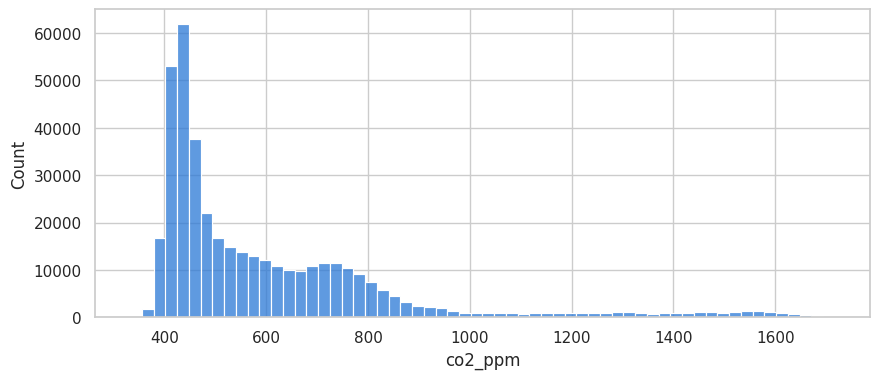

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

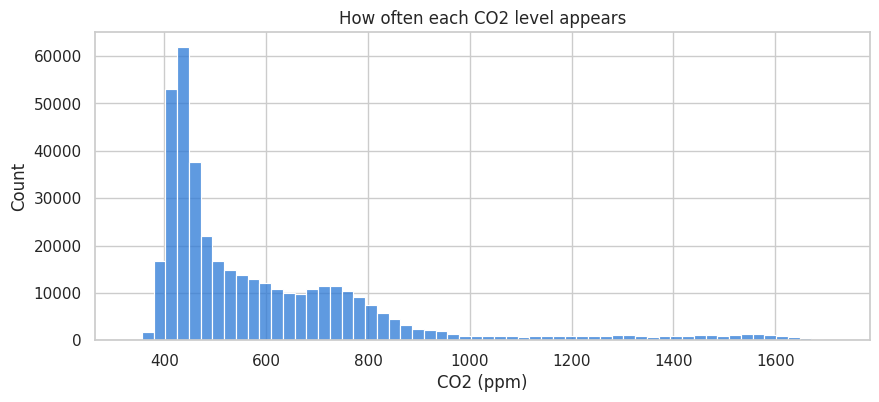

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

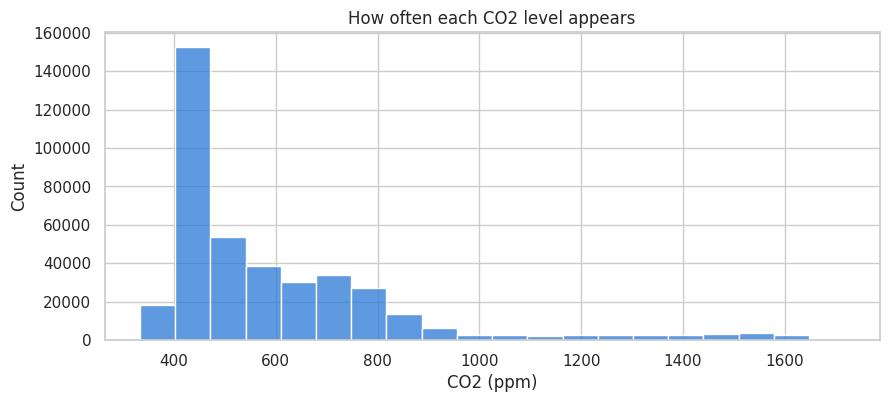

<IPython.core.display.Javascript object>

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

Most readings sit around 400–600 ppm (quiet rooms), with a long tail to the right (crowded times).
A long tail like this is called a right-skewed distribution.

⌨️ **Type this.** Add `hue=` to split the chart by a category. `element="step"` draws outlines so the
buildings don't hide each other.
```python
sns.histplot(data=df, x="co2_ppm", hue="building", element="step", bins=60)
plt.title("CO₂ levels by building")
plt.xlabel("CO₂ (ppm)")
plt.show()
```

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

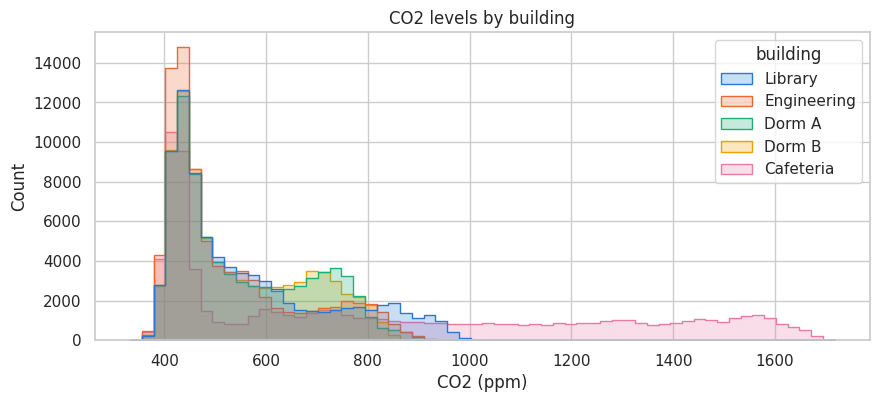

<IPython.core.display.Javascript object>

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** A box plot summarizes a distribution: the box holds the middle 50% of values, the line inside is the median, and dots are outliers far from the rest. Look closely at the chart.
Something is very wrong with some temperatures...
```python
sns.boxplot(data=df, x="temperature_c", y="building")
plt.title("Temperature by building (raw data)")
plt.xlabel("Temperature (°C)")
plt.ylabel("")
plt.show()
```

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12444 (\N{KATAKANA-HIRAGANA SEMI-VOICED SOUND MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


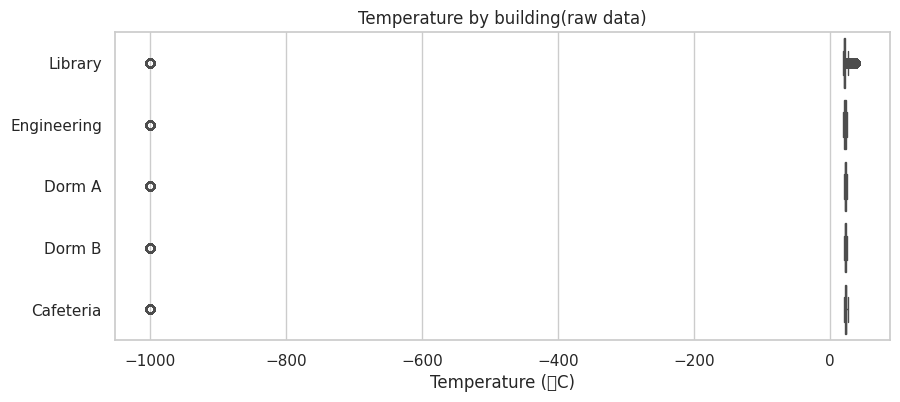

<IPython.core.display.Javascript object>

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

Those dots way out at -999 °C are a clue. Hold that thought for Level 2!

### 🎯 Case 1: How big is our data?
How many sensor readings (rows) did the campus collect this week? Type the number with no commas.

In [ ]:
# 🎯 Case 1: replace None with your answer, then run this cell
my_answer = 403200
submit(1, my_answer)

🎉 CASE 1 SOLVED! +10 points. Total score: 10


In [ ]:
scoreboard()

Score: 10 / 80    Rank: 🔰 Intern
Bugs logged: 1
  Case 1: ✅ solved
  Case 2: ⬜ open
  Case 3: ⬜ open
  Case 4: ⬜ open
  Case 5: ⬜ open
  Case 6: ⬜ open
  Case 7: ⬜ open


### ✍️ Your turn: solve it your own way
No code to copy this time. Use what you just learned to answer each question. There's usually more than one right answer!

✍️ **Your turn.** How many different **buildings** and different **sensors** are in the data?

<details><summary>💡 Hint</summary>

`.nunique()` counts the different values in a column, e.g. `df["building"].nunique()`.

</details>

In [ ]:
# ✍️ Your turn: write your own code here
n=df["building"].nunique()
print(n)

5


✍️ **Your turn.** What are the **first** and **last** timestamps in the data? How many days is that?

<details><summary>💡 Hint</summary>

Use `.min()` and `.max()` on `df["timestamp"]`. Subtracting two timestamps gives a time difference.

</details>

In [ ]:
# ✍️ Your turn: write your own code here
first=df["timestamp"].min()
last=df["timestamp"].max()
print(first,last)

2026-03-02 00:00:00 2026-03-08 23:59:00


✍️ **Your turn.** Make a **histogram of `humidity_pct`** with the seaborn recipe. Give it a title and an x-axis label.

<details><summary>💡 Hint</summary>

Start from the CO₂ histogram above and change the column, the title and the label.

</details>

Text(0.5, 0, 'humidity')

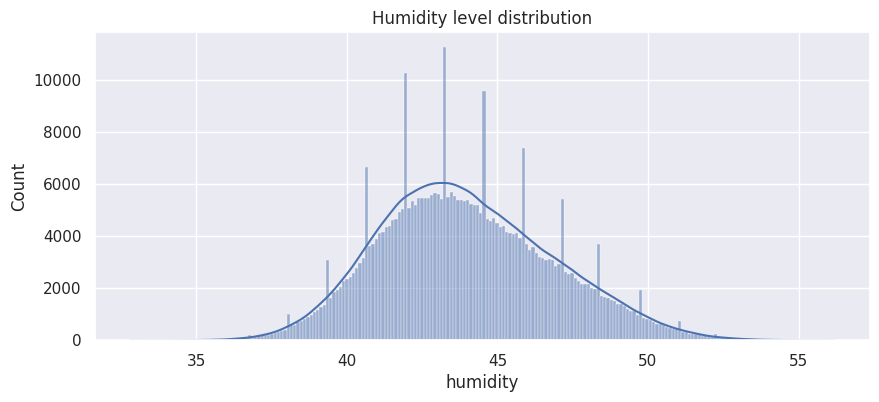

In [24]:
# ✍️ Your turn: write your own code here
sns.set_theme(style="darkgrid")
sns.histplot(data=df,x="humidity_pct",kde=True)
plt.title("Humidity level distribution")
plt.xlabel("humidity")

In [ ]:
# 🐞 BUG CHECK for Level 1. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Level 1", error="", fix="")

---
## Level 2: Dirty data

Real IoT devices glitch. When a sensor can't take a reading, many devices send a special sentinel value like `-999` instead of a real number. If we don't catch it, it will wreck every average we calculate.

⌨️ **Type this.** `.describe()` gives a quick summary of every numeric column.
Look at the min of `temperature_c`. Is -999 °C a real campus temperature?
```python
df.describe()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Comparing a column with `==` gives a column of `True`/`False`. This is
called a **boolean mask**.
```python
is_error = df["temperature_c"] == -999
is_error.head()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Python treats `True` as 1 and `False` as 0, so `.sum()` counts the errors.
```python
n_errors = is_error.sum()
print("Error readings:", n_errors)
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Now clean the data: replace -999 with `NaN` ("Not a Number"), which
pandas understands as missing and skips when it does math. Then count missing values per column.
```python
df["temperature_c"] = df["temperature_c"].replace(-999, np.nan)
df.isna().sum()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

Notice `humidity_pct` had missing values all along. Different sensors fail in different ways!

⌨️ **Type this.** Draw the same box plot again. What changed?
```python
sns.boxplot(data=df, x="temperature_c", y="building")
plt.title("Temperature by building (cleaned)")
plt.xlabel("Temperature (°C)")
plt.ylabel("")
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

> 🎉 Now the boxes are visible and the axis makes sense. The dots that remain on the right of one
> building are a different mystery... keep them in mind for Level 5.

### 🎯 Case 2: How many glitches?
How many temperature readings were the `-999` error code?

In [ ]:
# 🎯 Case 2: replace None with your answer, then run this cell
my_answer = None
submit(2, my_answer)

### ✍️ Your turn: solve it your own way
No code to copy this time. Use what you just learned to answer each question. There's usually more than one right answer!

✍️ **Your turn.** What **percent** of the humidity readings are missing?

<details><summary>💡 Hint</summary>

`.isna()` gives True/False, and `.mean()` of True/False values is the fraction that are True. Multiply by 100.

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

✍️ **Your turn.** Which **building** has the most missing temperature readings?

<details><summary>💡 Hint</summary>

Filter to the rows where `df["temperature_c"].isna()`, then use `["building"].value_counts()`.

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

In [ ]:
# 🐞 BUG CHECK for Level 2. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Level 2", error="", fix="")

---
## Level 3: Group and compare

CO₂ is a clue to how many people are in a room: people breathe out CO₂. Above about 1000 ppm, rooms feel stuffy and people get sleepy (yes, maybe even in class).

Group by is one of the most important ideas in data analysis:
*split* the data into groups, *apply* a calculation to each group, *combine* the results.

⌨️ **Type this.**
```python
co2_by_building = df.groupby("building")["co2_ppm"].mean().sort_values(ascending=False)
co2_by_building
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** seaborn's `barplot` calculates the averages for you. `order=` puts the bars
from highest to lowest and `errorbar=None` skips the error bars.
```python
sns.barplot(data=df, x="co2_ppm", y="building", order=co2_by_building.index, errorbar=None)
plt.title("Average CO₂ by building")
plt.xlabel("CO₂ (ppm)")
plt.ylabel("")
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

An average squashes thousands of readings into one number. **When** does CO₂ rise? Let's make a
**heatmap**: one row per building, one column per hour of the day, color = average CO₂.

⌨️ **Type this.** First add an `hour` column, then use `pivot_table` to build the grid.
```python
df["hour"] = df["timestamp"].dt.hour
co2_grid = df.pivot_table(index="building", columns="hour", values="co2_ppm", aggfunc="mean")

sns.heatmap(co2_grid, cmap="Blues", cbar_kws={"label": "CO₂ (ppm)"})
plt.title("Average CO₂ by building and hour of day")
plt.xlabel("Hour of day")
plt.ylabel("")
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

> 🤔 Can you spot breakfast, lunch and dinner? Which building is busy late at night?

### 🎯 Case 3: The stuffiest building
Which building has the highest average CO₂? Answer as text in quotes, e.g. `"Library"`.

In [ ]:
# 🎯 Case 3: replace None with your answer, then run this cell
my_answer = None
submit(3, my_answer)

### ✍️ Your turn: solve it your own way
No code to copy this time. Use what you just learned to answer each question. There's usually more than one right answer!

✍️ **Your turn.** Which building has the highest average **humidity**?

<details><summary>💡 Hint</summary>

Copy the idea of `co2_by_building`, but group the `humidity_pct` column instead.

</details>

In [ ]:
# Type your code here!

✍️ **Your turn.** At what **hour of the day** is CO₂ highest across the whole campus?

<details><summary>💡 Hint</summary>

Group by the `hour` column you made, take the mean of `co2_ppm`, then `.idxmax()` gives the label of the biggest value.

</details>

In [ ]:
# Type your code here!

✍️ **Your turn.** Make a **heatmap of average temperature** by building and hour, like the CO₂ one. Try a different color map such as `cmap="Reds"`.

<details><summary>💡 Hint</summary>

Build the grid with `pivot_table(..., values="temperature_c", ...)`, then pass it to `sns.heatmap`.

</details>

In [ ]:
# Type your code here!

In [ ]:
# 🐞 BUG CHECK for Level 3. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Level 3", error="", fix="")

---
## Level 4: The dying battery

IoT sensors often run on batteries. A dead sensor means blind spots in your data, so
maintenance teams need to know **which sensor to fix first**.

⌨️ **Type this.** Find the most recent timestamp, then keep only the rows from that moment
(one row per sensor). This is **filtering** with a boolean mask.
```python
last_time = df["timestamp"].max()
latest = df[df["timestamp"] == last_time]
latest[["sensor_id", "building", "battery_pct"]].sort_values("battery_pct").head()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Let's watch that sensor's battery over the week compared with a healthy one.
`.isin([...])` keeps rows whose sensor is in the list, and `hue=` draws one line per sensor.
```python
worst = latest.sort_values("battery_pct").iloc[0]["sensor_id"]
best = latest.sort_values("battery_pct").iloc[-1]["sensor_id"]
pair = df[df["sensor_id"].isin([worst, best])]

sns.lineplot(data=pair, x="timestamp", y="battery_pct", hue="sensor_id", errorbar=None)
plt.title("Battery level over the week")
plt.xlabel("")
plt.ylabel("Battery (%)")
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()


### 🎯 Case 4: Which sensor needs a new battery first?
Answer with the sensor ID in quotes, e.g. `"S05"`.

In [ ]:
# 🎯 Case 4: replace None with your answer, then run this cell
my_answer = None
submit(4, my_answer)

### ✍️ Your turn: solve it your own way
No code to copy this time. Use what you just learned to answer each question. There's usually more than one right answer!

✍️ **Your turn.** How many sensors had **less than 50% battery** at the last timestamp?

<details><summary>💡 Hint</summary>

Use the `latest` table. `(latest["battery_pct"] < 50)` is a boolean mask, and `.sum()` counts the True values.

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

✍️ **Your turn.** Which **building** has the lowest average battery at the last timestamp? Show it as a bar chart.

<details><summary>💡 Hint</summary>

Group `latest` by building and average `battery_pct`. For the chart, `sns.barplot(data=latest, x=..., y=..., errorbar=None)`.

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

In [ ]:
# 🐞 BUG CHECK for Level 4. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Level 4", error="", fix="")

---
## Level 5: The heat wave (time series)

Facilities got complaints that one building got *really* hot one afternoon. Was the
air conditioning (HVAC) broken? Let's find out when and where.

With 400,000+ readings, plotting every point is a mess. Instead we **resample**: group the
readings into 1-hour buckets and average each bucket. This is called **downsampling**, and
it's how IoT dashboards stay fast.

⌨️ **Type this.** `pd.Grouper(key="timestamp", freq="1h")` makes the 1-hour buckets.
`.unstack()` turns the buildings into columns.
```python
hourly = (df.groupby([pd.Grouper(key="timestamp", freq="1h"), "building"])["temperature_c"]
            .mean()
            .unstack())
print(hourly.shape)
hourly.head()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Plot one line per building. This time we use pandas' built-in `.plot()`,
which is a quick shortcut to matplotlib. It's handy when your table is already shaped like the chart.
```python
hourly.plot(title="Average temperature per building, hourly")
plt.ylabel("Temperature (°C)")
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Our eyes found the spike, now let Python find the exact hour.
`.stack()` folds the table back into one long list, and `.idxmax()` returns the *label*
(time, building) of the largest value.
```python
when, where = hourly.stack().idxmax()
print(f"Hottest hour: {where} on {when.day_name()} at {when.hour}:00")
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

### 🎯 Case 5: Where and when did the HVAC fail?
Answer with **two** pieces of text in parentheses: `("Building", "Dayname")`, e.g. `("Library", "Monday")`.

In [ ]:
# 🎯 Case 5: replace None with your answer, then run this cell
my_answer = None
submit(5, my_answer)

### ✍️ Your turn: solve it your own way
No code to copy this time. Use what you just learned to answer each question. There's usually more than one right answer!

✍️ **Your turn.** Make the hourly chart again, but for **`co2_ppm`** instead of temperature. Which building's line has three bumps every day? Why?

<details><summary>💡 Hint</summary>

Copy the `hourly` recipe and change the column. Save it under a new name (like `hourly_co2`) so you don't overwrite `hourly`, you'll need it later!

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

✍️ **Your turn.** What was the single **hottest reading** of the week, and which **sensor** recorded it?

<details><summary>💡 Hint</summary>

`df["temperature_c"].idxmax()` gives the row label of the hottest reading. `df.loc[label]` shows that whole row.

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

In [ ]:
# 🐞 BUG CHECK for Level 5. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Level 5", error="", fix="")

---
## Level 6: The suspicious sensor 🤖 (anomaly detection)

Security alert! One sensor might be **stuck** or even **tampered with**: it keeps reporting the
exact same temperature no matter what. Its data *looks* normal (22.5 °C is a perfectly
reasonable temperature) so a simple min/max check won't catch it.

The trick: real temperatures **wiggle**. The **standard deviation** measures how much a set of
numbers spreads out. A value that never changes has a standard deviation of **0**.

⌨️ **Type this.**
```python
temp_spread = df.groupby("sensor_id")["temperature_c"].std().sort_values()
temp_spread.head()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** A **z-score** says how unusual a value is compared with the others
(how many standard deviations away from the average). A sensor far from 0 (more than about 2 away) deserves a closer look.
```python
z = (temp_spread - temp_spread.mean()) / temp_spread.std()
z.head(3)
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** See it with your own eyes: the suspect vs. a typical sensor on Monday.
```python
suspect = temp_spread.index[0]
typical = temp_spread.index[20]
monday = df[df["timestamp"] < "2026-03-03"]

for sid in [suspect, typical]:
    one = monday[monday["sensor_id"] == sid]
    plt.plot(one["timestamp"], one["temperature_c"], label=sid)
plt.title("Monday temperature: suspect vs. typical sensor")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

### 🎯 Case 6: Which sensor is stuck?
Answer with the sensor ID in quotes.

In [ ]:
# 🎯 Case 6: replace None with your answer, then run this cell
my_answer = None
submit(6, my_answer)

### ✍️ Your turn: solve it your own way
No code to copy this time. Use what you just learned to answer each question. There's usually more than one right answer!

✍️ **Your turn.** Which **building** is the stuck sensor in?

<details><summary>💡 Hint</summary>

Filter `df` to the rows of the suspect sensor, then look at the `building` column (`.iloc[0]` gives its first value).

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

✍️ **Your turn.** Could a sensor also be stuck on **CO₂**? Find the 3 sensors with the smallest CO₂ standard deviation. Do any look suspicious?

<details><summary>💡 Hint</summary>

Same recipe as `temp_spread`, with `co2_ppm`. Compare their values with the rest. Is any near 0?

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

In [ ]:
# 🐞 BUG CHECK for Level 6. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Level 6", error="", fix="")

---
## BOSS LEVEL: Speed matters (vectorization)

Your boss wants a **CO₂ alert system**: count every reading above 1000 ppm.
There are two ways to do this in Python. Which do you think is faster? **Make a guess before you run it!**

1. A `for` loop that checks readings **one at a time**
2. A **vectorized** pandas operation that checks the **whole column at once**

⌨️ **Type this.**
```python
co2_list = df["co2_ppm"].tolist()

start = time.perf_counter()
count_loop = 0
for value in co2_list:
    if value > 1000:
        count_loop += 1
loop_seconds = time.perf_counter() - start

start = time.perf_counter()
count_vec = (df["co2_ppm"] > 1000).sum()
vec_seconds = time.perf_counter() - start

print(f"Loop:       {count_loop:,} alerts in {loop_seconds:.4f} seconds")
print(f"Vectorized: {count_vec:,} alerts in {vec_seconds:.4f} seconds")
print(f"Vectorized was about {loop_seconds / vec_seconds:.0f}x faster!")
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

Same answer, much faster. Now imagine 4 *billion* readings from a whole city instead of 400 thousand from one campus. That's why data scientists avoid loops over rows.

⌨️ **Type this.** Which buildings set off the alerts?
```python
alerts = df[df["co2_ppm"] > 1000]
alerts.groupby("building").size()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

### 🎯 Case 7 (BOSS): How many CO₂ alerts?
How many readings were above 1000 ppm?

In [ ]:
# 🎯 Case 7: replace None with your answer, then run this cell
my_answer = None
submit(7, my_answer)

### ✍️ Your turn: solve it your own way
No code to copy this time. Use what you just learned to answer each question. There's usually more than one right answer!

✍️ **Your turn.** How many readings are **both** stuffy (CO₂ above 1000) **and** warm (temperature above 24 °C)?

<details><summary>💡 Hint</summary>

Combine two masks with `&`, and put each condition in its own parentheses: `(df["co2_ppm"] > 1000) & (...)`.

</details>

In [ ]:
# ✍️ Your turn: write your own code here

✍️ **Your turn.** Which **hour of the day** sets off the most CO₂ alerts?

<details><summary>💡 Hint</summary>

`alerts` already has the `hour` column. Group it by hour, count rows with `.size()`, then use `.idxmax()`.

</details>

In [ ]:
# ✍️ Your turn: write your own code here

In [ ]:
# 🐞 BUG CHECK for Boss level. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Boss level", error="", fix="")

---
## 📊 Dashboard level: Many charts in one figure (subplots)

Real IoT dashboards show several charts side by side so you can compare them at a glance.
Each chart in the grid is called a **subplot**. The recipe:

```python
fig, axes = plt.subplots(nrows, ncols, figsize=(width, height))
```

* `fig` is the whole figure, the canvas everything is drawn on.
* `axes` holds one chart per spot in the grid. With **one row** you pick a chart with `axes[0]`, `axes[1]`, ...
  With **rows and columns** you use `axes[row, col]`. Counting starts at 0, so the top-left chart is `axes[0, 0]`.
* Every seaborn chart you made today takes an **`ax=`** argument that says which subplot to draw on.
* Set titles with `axes[0].set_title(...)` instead of `plt.title(...)`, because `plt.title` only changes the last chart.

⌨️ **Type this.** Two charts side by side: 1 row, 2 columns.
```python
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="co2_ppm", bins=60, ax=axes[0])
axes[0].set_title("CO₂ levels")

sns.boxplot(data=df, x="temperature_c", y="building", ax=axes[1])
axes[1].set_title("Temperature by building")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

`plt.tight_layout()` nudges the charts apart so titles and labels don't overlap.

✍️ **Complete the code.** Build a 2 × 2 campus dashboard. The top-left chart is done for you.
Replace every `___` to finish the other two, then design the bottom-right chart yourself.
(If you run it with a `___` left in, you'll get a `NameError`. That's a bug for your journal!)

<details><summary>💡 Hint</summary>

* Top right: the column is `"humidity_pct"` and the chart goes on `axes[0, 1]`.
* Bottom left: the data is `latest` (from Level 4) and the column is `"battery_pct"`. Any title in quotes works.
* Bottom right: copy one chart from today, then add `ax=axes[1, 1]`.

</details>

In [ ]:
# ✍️ Complete the code: replace every ___ with your own code, then press Shift + Enter

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Campus dashboard")

# Top left (done for you): average CO₂ by building
sns.barplot(data=df, x="co2_ppm", y="building", errorbar=None, ax=axes[0, 0])
axes[0, 0].set_title("Average CO₂ (ppm)")
axes[0, 0].set_ylabel("")

# Top right: average humidity by building
sns.barplot(data=df, x=___, y="building", errorbar=None, ax=___)
axes[0, 1].set_title("Average humidity (%)")
axes[0, 1].set_ylabel("")

# Bottom left: battery levels at the last timestamp (use the `latest` table from Level 4)
sns.histplot(data=___, x=___, bins=20, ax=axes[1, 0])
axes[1, 0].set_title(___)

# Bottom right: your choice! Any seaborn chart from today. Remember ax=axes[1, 1] and a title.


plt.tight_layout()
plt.show()

### The shortcut: one subplot per category

Making one subplot per building by hand means a lot of repeated code. seaborn's **figure-level** functions
(`displot`, `relplot` and `catplot`) build the grid for you:

* `col="building"` makes one subplot per building
* `col_wrap=3` starts a new row after 3 subplots
* `height=` sets the size of each subplot

⌨️ **Type this.**
```python
g = sns.displot(data=df, x="co2_ppm", col="building", col_wrap=3, bins=40, height=3)
g.set_titles("{col_name}")
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

✍️ **Complete the code.** Draw the hourly temperature from Level 5 with one subplot per building.
`relplot` needs **long** data (one row per hour and building), so the first line reshapes `hourly` for you.
Which building's subplot shows the heat wave?

<details><summary>💡 Hint</summary>

`hourly_long` has three columns: `timestamp`, `building` and `temperature_c`. Each `___` is one of those names, in quotes.

</details>

In [ ]:
# ✍️ Complete the code: replace every ___ with your own code, then press Shift + Enter

hourly_long = hourly.stack().reset_index(name="temperature_c")   # one row per (hour, building)

g = sns.relplot(data=hourly_long, kind="line", x=___, y=___,
                col=___, col_wrap=3, height=3, aspect=1.4)
g.set_titles("{col_name}")
plt.show()

✍️ **Your turn.** Build your own sensor subplots from scratch. Pick any sensor and make a figure with
**1 row and 3 columns** showing its hourly average **temperature**, **humidity** and **CO₂** over the week.
Give each subplot a title and the whole figure a title with `fig.suptitle(...)`.

<details><summary>💡 Hint</summary>

1. Keep one sensor's rows: `one = df[df["sensor_id"] == "S07"]`
2. Average each hour: `one.groupby(pd.Grouper(key="timestamp", freq="1h"))[["temperature_c", "humidity_pct", "co2_ppm"]].mean()`
3. Make the grid with `plt.subplots(1, 3, figsize=(15, 4))`, then draw each column with `sns.lineplot(data=..., x="timestamp", y="temperature_c", ax=axes[0])`.
   The hourly table keeps `timestamp` as its index, so add `.reset_index()` to make it a column.
4. Bonus: a `for` loop over `zip(axes, ["temperature_c", "humidity_pct", "co2_ppm"])` draws all three with one `sns.lineplot` line.

</details>

In [ ]:
# ✍️ Your turn: write your own code here, then press Shift + Enter

In [ ]:
# 🐞 BUG CHECK for the Dashboard level. Did you hit an error? Fill in what it said and what fixed it.
# More than one bug? Copy the log_error line once per bug. No bugs? Just run the cell.
log_error(level="Dashboard level", error="", fix="")

---
## Your own sensor dashboard

▶️ **Run this.** Explore any sensor and any measurement. If your setup has **ipywidgets**,
you'll get dropdown menus. If not, just change the two values on the last line and re-run.

In [ ]:
# ▶️ RUN THIS CELL. A mini interactive dashboard.
def plot_sensor(sensor_id="S01", measurement="temperature_c"):
    one = df[df["sensor_id"] == sensor_id]
    hourly_one = one.groupby(pd.Grouper(key="timestamp", freq="1h"))[measurement].mean()
    hourly_one.plot(title=f"{sensor_id} ({one['building'].iloc[0]}): {measurement}, hourly average")
    plt.xlabel("")
    plt.show()


try:
    import ipywidgets as widgets
    widgets.interact(plot_sensor,
                     sensor_id=sorted(df["sensor_id"].unique()),
                     measurement=["temperature_c", "humidity_pct", "co2_ppm", "battery_pct"])
except ImportError:
    print("ipywidgets isn't installed, no problem! Edit the values below and re-run this cell.")
    plot_sensor("S01", "temperature_c")

---
## 🌟 Extra credit: The crystal ball (predictive & prescriptive analytics)

This round is optional and worth up to **10 bonus points**.

Data analytics answers four kinds of questions, and you've already done the first two:

| Kind | Question it answers | Where you did it |
|---|---|---|
| **Descriptive** | What happened? | Levels 1–4: counting, cleaning, averaging |
| **Diagnostic** | Why did it happen? | Levels 5–6: finding the HVAC failure and the stuck sensor |
| **Predictive** | What *will* happen? | This round: forecasting when batteries run out |
| **Prescriptive** | What should we *do* about it? | This round: planning the maintenance trip |

Back in Level 4 you found the sensor with the dying battery. The boss doesn't just want to know when it's low. They want to know **when it will die**.

A simple way to predict the future is to draw the **best straight line** through the data and extend it.
This is called **linear regression**. `np.polyfit(x, y, 1)` finds the line `y = slope * x + intercept`
that fits best (the `1` means a straight line). The **slope** is how much battery is lost per day.

⌨️ **Type this.** First turn each timestamp into "days since the start", because `polyfit` needs numbers.
```python
dying = df[df["sensor_id"] == worst]
days = (dying["timestamp"] - dying["timestamp"].min()).dt.total_seconds() / 86400
slope, intercept = np.polyfit(days, dying["battery_pct"], 1)
print(f"{worst} loses about {-slope:.1f}% battery per day")
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** The line hits 0% when `slope * days + intercept = 0`, which is at `days = -intercept / slope`.
Then draw the measurements with the forecast line (`"--"` makes it dashed) extended into the future.
```python
days_to_empty = -intercept / slope
empty_at = dying["timestamp"].min() + pd.Timedelta(days=days_to_empty)
print(f"Forecast: {worst} runs out on {empty_at:%A, %B %d at %H:%M}")

future = np.linspace(0, days_to_empty, 50)
plt.plot(dying["timestamp"], dying["battery_pct"], label="measured")
plt.plot(dying["timestamp"].min() + pd.to_timedelta(future, unit="D"),
         slope * future + intercept, "--", label="forecast")
plt.title(f"{worst}: when will the battery run out?")
plt.ylabel("Battery (%)")
plt.legend()
plt.show()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

### 🎯 Case 8 (extra credit): Plan the maintenance trip
How many new batteries should the technician bring? (Every sensor predicted to run out within 105 days needs one.)

In [ ]:
# 🎯 Case 8 (extra credit): replace None with your answer, then run this cell
my_answer = None
submit(8, my_answer)

---
## 🐞 Bug Journal review

⌨️ **Type this.** See every bug you logged today.
```python
journal = show_error_log()
journal
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Which kinds of error did you hit most? `.str.split(":").str[0]` keeps just the
error type (the part before the colon), and `value_counts()` counts each one.
```python
journal["error"].str.split(":").str[0].value_counts()
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

⌨️ **Type this.** Save your journal as a CSV file.
```python
journal.to_csv("my_bug_journal.csv", index=False)
print("Saved", len(journal), "bugs to my_bug_journal.csv")
```

In [ ]:
# ⌨️ Run this cell, type the code from above into the box, then press Shift + Enter in the box
type_here()

---
## 🏆 Final score

▶️ **Run this** to see your rank.

In [ ]:
scoreboard()

### Debrief questions (discuss with a partner)

1. In Level 2, what would the average temperature have been if we hadn't removed the -999 values? Try it!
2. The stuck sensor reported a believable temperature. Why is that more dangerous than an obviously wrong value like -999?
3. Why did we average into 1-hour buckets before plotting? What could we miss by doing that?


**Case closed. Great work, detective!**